In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp

In [ ]:
Пусть Zn – количество частиц в n-м поколении ветвящегося процесса (ВП) Гальтона-Ватсона (Z0 = 1)
с геометрическим распределением (с параметром p) числа потомков.

E = 1-p / p
D = 1-p / p^2

In [ ]:
1. Оценить вероятность вырождения ВП по множеству симуляций и сравнить с точным ответом.

In [53]:
def branch(p, n):
    z = [0]*n
    z[0] = 1
    for k in range (1, n):
        z[k] = sc.stats.nbinom.rvs(z[k-1], p)
        if z[k] == 0:
            break
    return z
p = 1/3
n = 10
N = 100 # симуляций

death_hat = 0
for _ in range(N):
    if branch(p, n)[n-1] == 0:
        death_hat += 1/N
print("true death prob = ", p/(1-p), "estimation = ", death_hat)

true death prob =  0.49999999999999994 estimation =  0.5200000000000002


In [ ]:
2. Смоделировать критический процесс 1000 раз до момента вырождения или до 50-го хода, отобрать
траектории, которые через 50 ходов еще живы, вывести их. Как их количество и численность
соответствующих процессов согласуется с предельной теоремой для ВП?
Сколько траекторий проживет 50 ходов в случае докритического процесса с геометрическ с p >
1/2? Моделировать процесс для различных p.

P(Zn>0) ~  0.02 доля выживших : 0.016


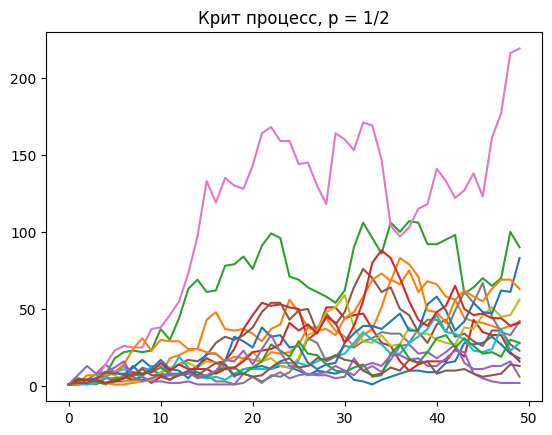

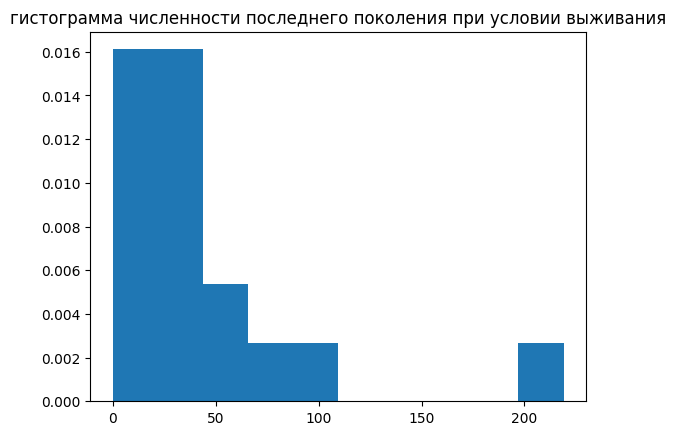

P(Zn>0) ~  0.14363803801297456 доля выживших : 0.006


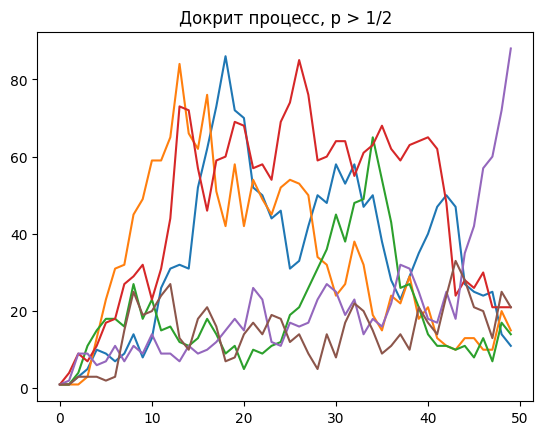

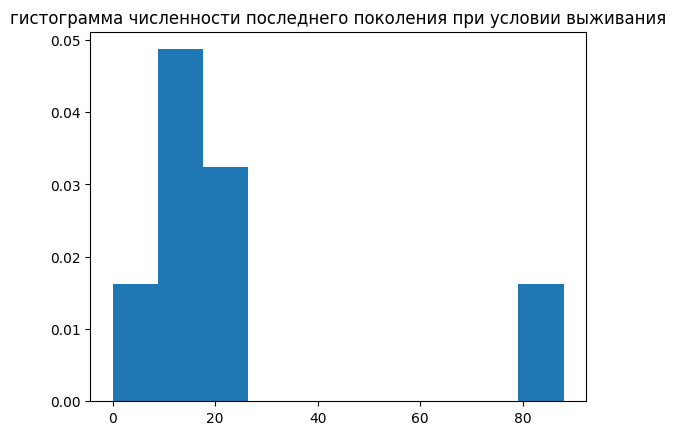

In [10]:
def branch(p, n):
    z = [0]*n
    z[0] = 1
    for k in range (1, n):
        z[k] = sc.stats.nbinom.rvs(z[k-1], p)
        if z[k] == 0:
            break
    return z
    
N = 1000 # число процессов
n = 50 # число поколений в процессе
p = 1/2

l = [j for j in range(n)]
survivors = 0 # число выживших процессов
pop = [0] # сам процесс

for k in range(N):
    z = branch(p, n)
    if z[n-1] != 0:
        survivors += 1
        pop.append(z[n-1])
        plt.plot(l, z)
print("P(Zn>0) ~ ", 2/ (n* (1-p) / p**2), "доля выживших :", survivors/N)
plt.title("Крит процесс, p = 1/2")
plt.show()

plt.hist(pop, density = "true")
plt.title("гистограмма численности последнего поколения при условии выживания")
plt.show()

p = 1/2 + 1/100
l = [j for j in range(n)]
survivors = 0 # число выживших процессов
pop = [0] # сам процесс

for k in range(N):
    z = branch(p, n)
    if z[n-1] != 0:
        survivors += 1
        pop.append(z[n-1])
        plt.plot(l, z)
print("P(Zn>0) ~ ", ( (1-p)/p )**n * 2/((1-p) / p**2), "доля выживших :", survivors/N)
plt.title("Докрит процесс, p > 1/2")
plt.show()

plt.hist(pop, density = "true")
plt.title("гистограмма численности последнего поколения при условии выживания")
plt.show()

In [ ]:
3. Смоделировать 20 шагов надкритического процесса с p = 0.45, построить график log Zn от n.
Построить несколько траекторий таких процессов.

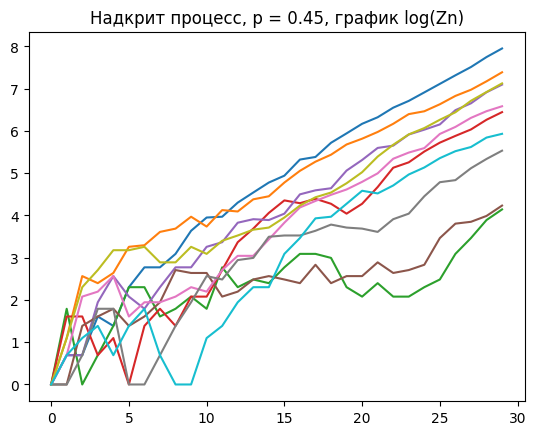

In [54]:
def branch(p, n):
    z = [0]*n
    z[0] = 1
    for k in range (1, n):
        z[k] = sc.stats.nbinom.rvs(z[k-1], p)
        if z[k] == 0:
            break
    return z
p = 0.45
n = 30
N = 50 # симуляций
l = [j for j in range(n)]

for k in range(N):
    z = branch(p, n)
    if z[n-1] != 0:
        plt.plot(l, np.log(z))
plt.title("Надкрит процесс, p = 0.45, график log(Zn)")
plt.show()

In [ ]:
4. Рассмотрим докритический ВП с иммиграцией в одну частицу. Найти численно вероятность того,
что в процессе k частиц в момент n, где k ≤ 5.

In [55]:
def branch_immigration(p, n):
    z = [0]*n
    z[0] = 1
    for k in range (1, n):
        z[k] = sc.stats.nbinom.rvs(z[k-1], p) + 1
        if z[k] == 0:
            break
    return z
p = 0.6
n = 10
N = 100 # симуляций
probs = [0 for _ in range(6)]
for k in range(N):
    z = branch_immigration(p, n)
    for k in range(6):
        if z[n-1] == k:
            probs[k] += 1/N
print(probs)

[0, 0.36000000000000015, 0.15, 0.16, 0.12999999999999998, 0.05]


In [ ]:
5*. Рассмотрим а) надкритический, б) критический ВП. Моделировать процесс в течении 20 поколений
(дождавшись невырождения).
Оценить с помощью ОМП среднее число потомков одной частицы и вероятность того, что частица

дает ровно 0 потомков, а также вероятность того, что частица дает ровно одного потомка. Срав-
нить оценки с реальными значениями.

Задача также приносит 0.5 баллов по факультативу за 5 семинар

In [73]:
def branch(p, n):
    z = [0]*n
    z[0] = 1
    for k in range (1, n):
        z[k] = sc.stats.nbinom.rvs(z[k-1], p)
        if z[k] == 0:
            break
    return z
p = 0.4
n = 20

while 1:
    z = branch(p, n)
    if z[n-1] != 0:
        break
        
mu_hat = (np.sum(z)-1) / (np.sum(z) - z[n-1])
print("mu = ", (1-p)/p, ", mle = ",mu_hat)

p_hat = 1/(mu_hat + 1)
print("p = ", p, ", mle = ", p_hat)

print("P(X = 1) = ", p*(1-p), ", mle = ", p_hat*(1-p_hat), end = "\n\n")




p = 0.7
n = 10
while 1:
    z = branch(p, n)
    if z[n-1] != 0:
        break
        
mu_hat = (np.sum(z)-1) / (np.sum(z) - z[n-1])
print("mu = ", (1-p)/p, ", mle = ",mu_hat)

p_hat = 1/(mu_hat + 1)
print("p = ", p, ", mle = ", p_hat)

print("P(X = 1) = ", p*(1-p), ", mle = ", p_hat*(1-p_hat))

mu =  1.4999999999999998 , mle =  1.475544531431672
p =  0.4 , mle =  0.4039515295738485
P(X = 1) =  0.24 , mle =  0.2407746913287967

mu =  0.42857142857142866 , mle =  1.08
p =  0.7 , mle =  0.4807692307692307
P(X = 1) =  0.21000000000000002 , mle =  0.2496301775147929
